In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import urllib.request
import zipfile
import os

url = "https://archive.ics.uci.edu/static/public/292/wholesale+customers.zip"

urllib.request.urlretrieve(url, "customers.zip")

with zipfile.ZipFile("customers.zip", "r") as z:
    z.extractall("customer_data")

df = pd.read_csv("customer_data/Wholesale customers data.csv")

print("Dataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Dataset Shape: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [2]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Select spending features for clustering
X = df[['Fresh', 'Milk', 'Grocery',
        'Frozen', 'Detergents_Paper', 'Delicassen']]

# Standardize the data
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nOriginal Data Shape:", X.shape)
print("Scaled Data Shape:", X_scaled.shape)
print("\nData Preprocessing Completed!")

Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Duplicate Records: 0

Original Data Shape: (440, 6)
Scaled Data Shape: (440, 6)

Data Preprocessing Completed!


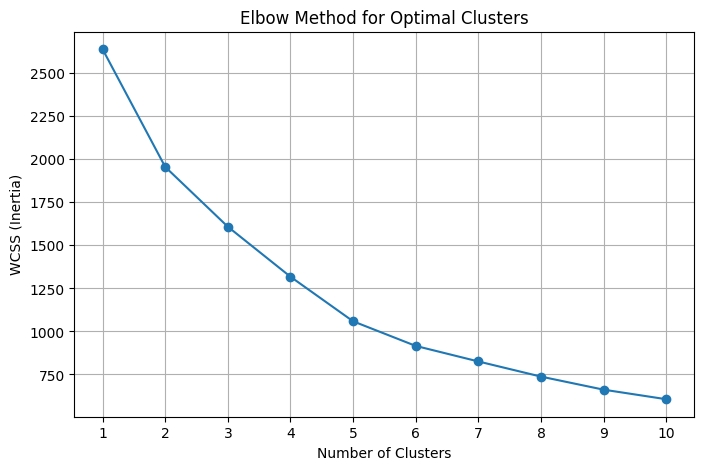

In [3]:
from sklearn.cluster import KMeans

wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS (Inertia)")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [4]:
# Apply K-Means Clustering

kmeans = KMeans(
    n_clusters=4,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")

print("\nCustomer Count in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

display(df.head(10))

K-Means Clustering Completed!

Customer Count in Each Cluster:
Cluster
0    110
1    315
2     10
3      5
Name: count, dtype: int64


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,0
2,2,3,6353,8808,7684,2405,3516,7844,0
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1
5,2,3,9413,8259,5126,666,1795,1451,1
6,2,3,12126,3199,6975,480,3140,545,1
7,2,3,7579,4956,9426,1669,3321,2566,1
8,1,3,5963,3648,6192,425,1716,750,1
9,2,3,6006,11093,18881,1159,7425,2098,0


In [5]:
from sklearn.metrics import silhouette_score

print("Silhouette Score:", round(
    silhouette_score(X_scaled, df['Cluster']), 3
))

print("\nChecking Different Cluster Counts:")

for k in range(2, 7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"Clusters: {k}, Silhouette Score: {score:.3f}")

Silhouette Score: 0.348

Checking Different Cluster Counts:
Clusters: 2, Silhouette Score: 0.547
Clusters: 3, Silhouette Score: 0.548
Clusters: 4, Silhouette Score: 0.348
Clusters: 5, Silhouette Score: 0.369
Clusters: 6, Silhouette Score: 0.378


In [6]:
# Final K-Means Model with 3 Clusters

final_kmeans = KMeans(
    n_clusters=3,
    init='k-means++',
    random_state=42,
    n_init=10
)

df['Cluster'] = final_kmeans.fit_predict(X_scaled)

print("Final K-Means Model Completed!")

print("\nCustomer Distribution:")
print(df['Cluster'].value_counts().sort_index())

print("\nFinal Silhouette Score:",
      round(silhouette_score(X_scaled, df['Cluster']), 3))

Final K-Means Model Completed!

Customer Distribution:
Cluster
0     45
1    393
2      2
Name: count, dtype: int64

Final Silhouette Score: 0.548


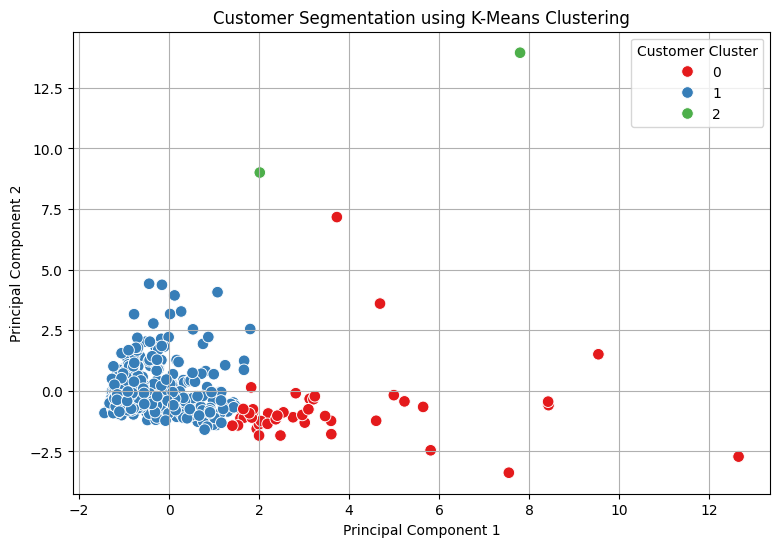

In [7]:
from sklearn.decomposition import PCA

# Reduce 6 features into 2 dimensions
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df['Cluster'],
    palette='Set1',
    s=70
)

plt.title("Customer Segmentation using K-Means Clustering")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Customer Cluster")
plt.grid(True)
plt.show()

In [9]:
# Analyze Average Spending in Each Cluster

cluster_analysis = df.groupby('Cluster')[
    ['Fresh', 'Milk', 'Grocery',
     'Frozen', 'Detergents_Paper', 'Delicassen']
].mean().round(2)

print("CUSTOMER CLUSTER CHARACTERISTICS")
display(cluster_analysis)

# Customer count and average spending
print("\nCluster Summary:")
print(df.groupby('Cluster').agg(
    Customer_Count=('Cluster', 'count'),
    Average_Fresh=('Fresh', 'mean'),
    Average_Milk=('Milk', 'mean'),
    Average_Grocery=('Grocery', 'mean'),
    Average_Frozen=('Frozen', 'mean')
).round(2))

CUSTOMER CLUSTER CHARACTERISTICS


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,10440.93,19386.42,28656.09,2190.24,13327.80,2374.20
1,12062.91,4115.10,5534.97,2940.68,1696.17,1299.11
2,34782.00,30367.00,16898.00,48701.50,755.50,26776.00



Cluster Summary:
         Customer_Count  Average_Fresh  Average_Milk  Average_Grocery  \
Cluster                                                                 
0                    45       10440.93      19386.42         28656.09   
1                   393       12062.91       4115.10          5534.97   
2                     2       34782.00      30367.00         16898.00   

         Average_Frozen  
Cluster                  
0               2190.24  
1               2940.68  
2              48701.50  


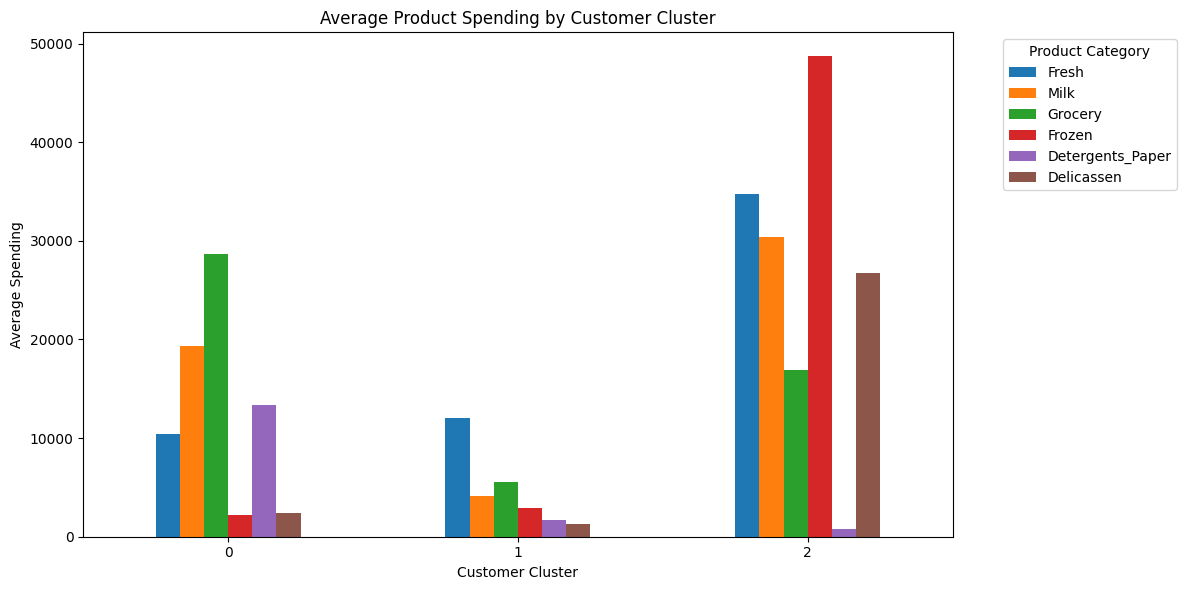

In [10]:
# Cluster Spending Comparison

cluster_analysis.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Average Product Spending by Customer Cluster")
plt.xlabel("Customer Cluster")
plt.ylabel("Average Spending")
plt.xticks(rotation=0)
plt.legend(title="Product Category", bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()